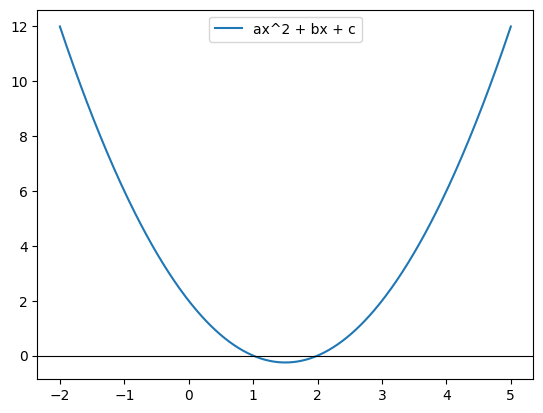

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import math

a, b, c = 1, -3, 2   # Example: x^2 - 3x + 2 = 0
x = np.linspace(-2, 5, 400)
y = a*x**2 + b*x + c

plt.plot(x, y, label="ax^2 + bx + c")
plt.axhline(0, color="black", linewidth=0.8)
plt.legend()
plt.show()


In [2]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

In [3]:
class QuadState(TypedDict):

    a: int
    b: int
    c: int

    equation: str
    discriminant: float

    result: str

In [64]:
# Defining nodes
def show_equation(state: QuadState) ->QuadState:

    equation = f"{state['a']}x2{state['b']}x{state['c']}"

    return {"equation": equation}

#-------------------------------------------------------------------------------------------

def calc_discriminant(state: QuadState) ->QuadState:

    d = (state['b']**2) - (4*state['a']*state['c'])

    return {'discriminant': d}

#-------------------------------------------------------------------------------------------

def real_roots(state: QuadState) ->QuadState:

    root1 = (-state['b'] + math.sqrt(state['discriminant'])) / (2*state['a'])
    root2 = (-state['b'] - math.sqrt(state['discriminant'])) / (2*state['a'])

    result = f"The two real roots of this equation are {round(root1,2)} and {round(root2,2)}"
    
    return {"result": result}
    
#-------------------------------------------------------------------------------------------

def repeated_root(state: QuadState) ->QuadState:

    root = (-state['b']) / (2*state['a'])

    result = f"The only repeating root of this equation is {root}"
    
    return {"result": result}

#-------------------------------------------------------------------------------------------

def no_real_root(state: QuadState) ->QuadState:

    result = f"There is no real root to this equation."
    
    return {"result": result}



In [65]:
# Defining condition
# check_condition is not same as a node, it is a simple function to imply the condition

def check_condition(state: QuadState) -> Literal['real_roots', 'repeated_root', 'no_real_root']:

    if state['discriminant'] > 0:
        return "real_roots"
    elif state['discriminant'] == 0:
        return "repeated_root"
    elif state['discriminant'] < 0:
        return "no_real_root"

In [66]:
a = QuadState({'a': 4, 'b': -5, 'c': -4})
show_equation(a)

{'equation': '4x2-5x-4'}

In [67]:
graph = StateGraph(QuadState)

# Adding nodes
graph.add_node("show_equation", show_equation)
graph.add_node('calc_discriminant', calc_discriminant)
graph.add_node('real_roots', real_roots)
graph.add_node('no_real_root', no_real_root)
graph.add_node('repeated_root', repeated_root)


# Adding edges
graph.add_edge(START, "show_equation")
graph.add_edge("show_equation", "calc_discriminant")
graph.add_conditional_edges('calc_discriminant', check_condition)   # check_condition is not a node, it is a simple function
graph.add_edge('real_roots', END)
graph.add_edge('repeated_root', END)
graph.add_edge('no_real_root', END)

# Compiling graph
workflow = graph.compile()

In [70]:
initial_state = {
    "a":4,
"b": 5,
"c": -4}

workflow.invoke(initial_state)

{'a': 4,
 'b': 5,
 'c': -4,
 'equation': '4x25x-4',
 'discriminant': 89,
 'result': 'The two real roots of this equation are 0.55 and -1.8'}

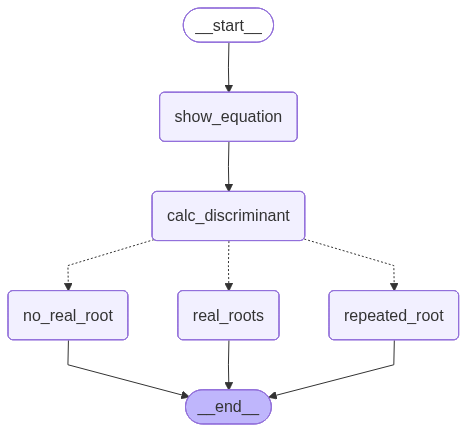

In [69]:
workflow    # Dotted lines indicates conditional stage.

# In next notebook, we will use LLM with conditional workflow.

# ***Thankyou***